In [ ]:

# Install KaggleHub
!pip install -q kagglehub

import os
import glob
import pandas as pd
import kagglehub

# European Credit Card Fraud Detection dataset
dataset = "mlg-ulb/creditcardfraud"

# Download dataset
dataset_path = kagglehub.dataset_download(dataset)

print("Dataset downloaded to:")
print(dataset_path)

# Find CSV files
csv_files = glob.glob(
    os.path.join(dataset_path, "**", "*.csv"),
    recursive=True
)

print("\nCSV files found:")
for file in csv_files:
    print(file)

if not csv_files:
    raise FileNotFoundError(
        "No CSV file was found in the Kaggle dataset."
    )

# Load the CSV
csv_file = csv_files[0]

print("\nLoading:")
print(csv_file)

df = pd.read_csv(csv_file)

# Verify the dataset
print("\nDataset loaded successfully!")
print("Shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nFraud class distribution:")
print(df["Class"].value_counts())

print("\nFraud percentage:")
print((df["Class"].value_counts(normalize=True) * 100).round(4))

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Dataset downloaded to:
/kaggle/input/creditcardfraud

CSV files found:
/kaggle/input/creditcardfraud/creditcard.csv

Loading:
/kaggle/input/creditcardfraud/creditcard.csv

Dataset loaded successfully!
Shape: (284807, 31)

First 5 rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Fraud class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud percentage:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


In [ ]:
# Data Handling
import pandas as pd
import numpy as np
import joblib

# Data Splitting and Cross-Validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    RandomizedSearchCV
)

# Feature Preprocessing
# from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.preprocessing import  StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

# Model Evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    # f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

# Data Visualization
import matplotlib.pyplot as plt

In [ ]:

# STEP 1: Dataset exploration and validation

import pandas as pd
import numpy as np

# 1. Dataset shape
print("Dataset shape:", df.shape)

# 2. Data types
print("\nData types:")
print(df.dtypes.value_counts())

# 3. Missing values
print("\nMissing values:")
print("Total missing values:", df.isnull().sum().sum())

missing = df.isnull().sum()
print(missing[missing > 0])

# 4. Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 5. Target distribution
print("\nClass distribution:")
print(df["Class"].value_counts())

print("\nClass percentages:")
print(
    (df["Class"].value_counts(normalize=True) * 100)
    .round(4)
)

# 6. Amount statistics by class
print("\nTransaction amount statistics:")
display(
    df.groupby("Class")["Amount"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

# 7. Summary statistics
print("\nSummary statistics:")
display(df[["Time", "Amount"]].describe().round(2))

Dataset shape: (284807, 31)

Data types:
float64    30
int64       1
Name: count, dtype: int64

Missing values:
Total missing values: 0
Series([], dtype: int64)

Duplicate rows: 1081

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class percentages:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64

Transaction amount statistics:


,count,mean,median,std,min,max
Class,,,,,,
0,284315,88.29,22.00,250.11,0.0,25691.16
1,492,122.21,9.25,256.68,0.0,2125.87



Summary statistics:


,Time,Amount
count,284807.00,284807.00
mean,94813.86,88.35
std,47488.15,250.12
min,0.00,0.00
25%,54201.50,5.60
50%,84692.00,22.00
75%,139320.50,77.16
max,172792.00,25691.16


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print(df["Class"].value_counts() )


print("Duplicate rows:", df.duplicated().sum())
print("Duplicates by class:\n", df[df.duplicated()]["Class"].value_counts())

print("Before:", df.shape, "| fraud:", df["Class"].sum())
df = df.drop_duplicates().reset_index(drop=True)
print("After: ", df.shape, "| fraud:", df["Class"].sum())


Duplicate rows: 1081
Class
0    284315
1       492
Name: count, dtype: int64
Duplicate rows: 1081
Duplicates by class:
 Class
0    1062
1      19
Name: count, dtype: int64
Before: (284807, 31) | fraud: 492
After:  (283726, 31) | fraud: 473


In [ ]:
feature_cols = [c for c in df.columns if c not in ("Time", "Class")]
X = df[feature_cols]
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(226980, 29) (56746, 29)
Class
0    0.998335
1    0.001665
Name: proportion, dtype: float64
Class
0    0.998326
1    0.001674
Name: proportion, dtype: float64


In [ ]:
numeric_cols = feature_cols
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
    ]
)

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print(X_train_prepared.shape)
print(X_test_prepared.shape)

(226980, 29)
(56746, 29)


In [ ]:
log_model = LogisticRegression(class_weight="balanced", max_iter=1000)

log_model.fit(X_train_prepared, y_train)

y_pred = log_model.predict(X_test_prepared)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, log_model.predict_proba(X_test_prepared)[:, 1]))

[[55247  1404]
 [   12    83]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.10        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746

ROC AUC: 0.9648317630849644


In [ ]:
rf_model = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                  random_state=42, n_jobs=-1)
rf_model.fit(X_train_prepared, y_train)
rf_pred = rf_model.predict(X_test_prepared)

print(confusion_matrix(y_test, rf_pred))
print(classification_report(y_test, rf_pred))
print("ROC AUC:", roc_auc_score(y_test, rf_model.predict_proba(X_test_prepared)[:, 1]))

[[56650     1]
 [   28    67]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.99      0.71      0.82        95

    accuracy                           1.00     56746
   macro avg       0.99      0.85      0.91     56746
weighted avg       1.00      1.00      1.00     56746

ROC AUC: 0.9299132546552344


In [ ]:
for name, model in [("Logistic", log_model), ("Random Forest", rf_model)]:
    proba = model.predict_proba(X_test_prepared)[:, 1]
    print(name,
          "| AUC:", round(roc_auc_score(y_test, proba), 3),
          "| Avg precision:", round(average_precision_score(y_test, proba), 3))

Logistic | AUC: 0.965 | Avg precision: 0.675
Random Forest | AUC: 0.93 | Avg precision: 0.808


In [ ]:
proba = rf_model.predict_proba(X_test_prepared)[:, 1]

for t in [0.1, 0.2, 0.3, 0.5, 0.7]:
    pred = (proba >= t).astype(int)
    print(t,
          "precision:", round(precision_score(y_test, pred, zero_division=0), 3),
          "recall:", round(recall_score(y_test, pred), 3))

0.1 precision: 0.865 recall: 0.811
0.2 precision: 0.926 recall: 0.789
0.3 precision: 0.946 recall: 0.737
0.5 precision: 0.985 recall: 0.705
0.7 precision: 0.983 recall: 0.621


In [ ]:
names = preprocessor.get_feature_names_out()
importance = pd.Series(rf_model.feature_importances_, index=names)
print(importance.sort_values(ascending=False).head(10))

num__V10    0.162091
num__V14    0.131664
num__V4     0.118852
num__V12    0.103519
num__V11    0.090041
num__V17    0.068803
num__V3     0.055394
num__V7     0.045159
num__V16    0.039176
num__V2     0.020765
dtype: float64


In [13]:
param_dist = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", 0.3],
}

search = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=10, cv=3, scoring="average_precision",
    random_state=42, n_jobs=1, verbose=1
)
search.fit(X_train_prepared, y_train)

print(search.best_params_)
print("CV avg precision:", round(search.best_score_, 3))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
{'n_estimators': 500, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}
CV avg precision: 0.847


In [14]:
base = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                              random_state=42, n_jobs=-1)

base_scores = cross_val_score(base, X_train_prepared, y_train,
                              cv=3, scoring="average_precision")
print(base_scores.round(3), round(base_scores.mean(), 3))

[0.791 0.881 0.848] 0.84


In [15]:
gb = HistGradientBoostingClassifier(
    max_depth=5, learning_rate=0.1, max_iter=300,
    class_weight="balanced", random_state=42
)

gb_scores = cross_val_score(gb, X_train_prepared, y_train,
                            cv=3, scoring="average_precision")
print(gb_scores.round(3), round(gb_scores.mean(), 3))

[0.778 0.762 0.805] 0.782


In [16]:
results = pd.DataFrame({
    "model": ["Random forest (baseline)", "Random forest (tuned)", "HistGradientBoosting"],
    "cv_avg_precision": [base_scores.mean(), search.best_score_, gb_scores.mean()]
}).round(3)
print(results)

                      model  cv_avg_precision
0  Random forest (baseline)             0.840
1     Random forest (tuned)             0.847
2      HistGradientBoosting             0.782


In [17]:
rf_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                     random_state=42, n_jobs=-1)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Use RAW X_train: the pipeline re-fits the scaler inside each fold
oof_proba = cross_val_predict(rf_pipe, X_train, y_train,
                              cv=cv, method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
best = np.argmax(f1[:-1])
best_t = thr[best]

print("Best threshold:", round(best_t, 3),
      "| precision:", round(prec[best], 3),
      "| recall:", round(rec[best], 3),
      "| F1:", round(f1[best], 3))

Best threshold: 0.32 | precision: 0.917 | recall: 0.815 | F1: 0.863


In [18]:
rf_pipe.fit(X_train, y_train)

test_proba = rf_pipe.predict_proba(X_test)[:, 1]
final_pred = (test_proba >= best_t).astype(int)

print(confusion_matrix(y_test, final_pred))
print(classification_report(y_test, final_pred))
print("Avg precision:", round(average_precision_score(y_test, test_proba), 3))

[[56647     4]
 [   25    70]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.95      0.74      0.83        95

    accuracy                           1.00     56746
   macro avg       0.97      0.87      0.91     56746
weighted avg       1.00      1.00      1.00     56746

Avg precision: 0.808


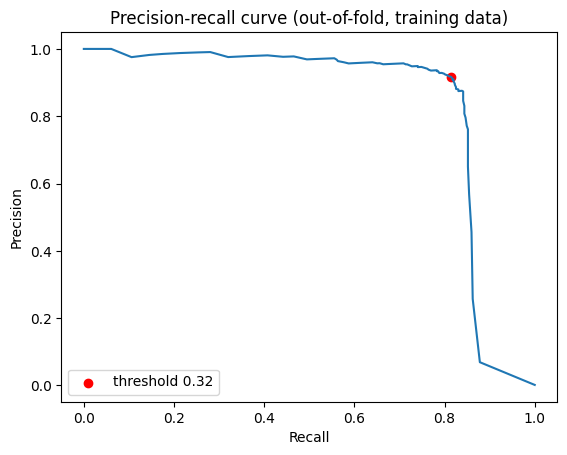

In [19]:
plt.plot(rec, prec)
plt.scatter(rec[best], prec[best], color="red", label=f"threshold {best_t:.2f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall curve (out-of-fold, training data)")
plt.legend()
plt.show()

In [20]:
joblib.dump(
    {"model": rf_pipe, "threshold": best_t, "features": feature_cols},
    "fraud_model.joblib"
)

# Verify the saved file works
saved = joblib.load("fraud_model.joblib")
check = (saved["model"].predict_proba(X_test[saved["features"]])[:, 1]
         >= saved["threshold"]).astype(int)
print("Reloaded model matches:", (check == final_pred).all())

Reloaded model matches: True


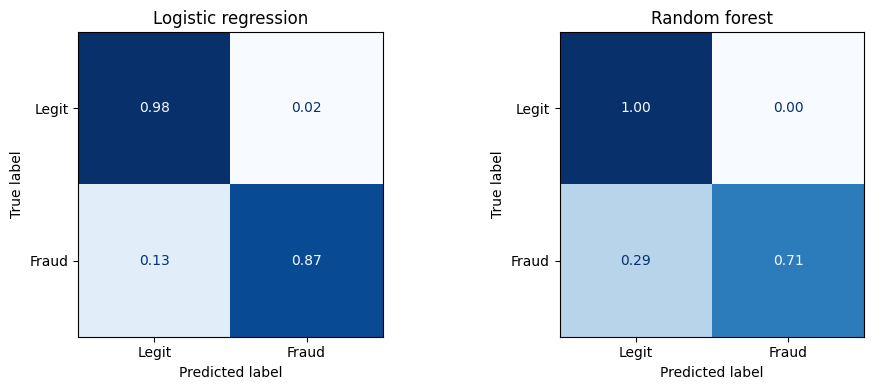

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, [("Logistic regression", log_model),
                                    ("Random forest", rf_model)]):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test_prepared, y_test, ax=ax, normalize="true",
        values_format=".2f", cmap="Blues", colorbar=False,
        display_labels=["Legit", "Fraud"])
    ax.set_title(name)
plt.tight_layout()
plt.show()

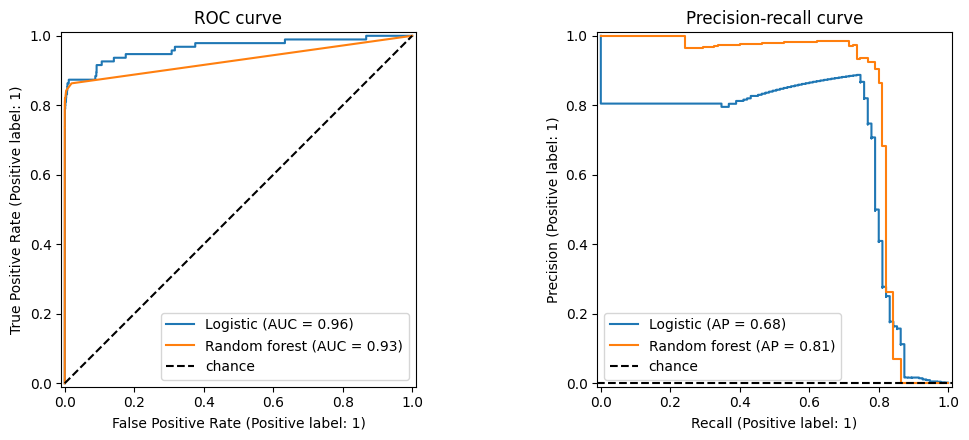

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, model in [("Logistic", log_model), ("Random forest", rf_model)]:
    proba = model.predict_proba(X_test_prepared)[:, 1]
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=name, ax=axes[1])

axes[0].plot([0, 1], [0, 1], "k--", label="chance")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="chance")
axes[0].set_title("ROC curve")
axes[1].set_title("Precision-recall curve")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

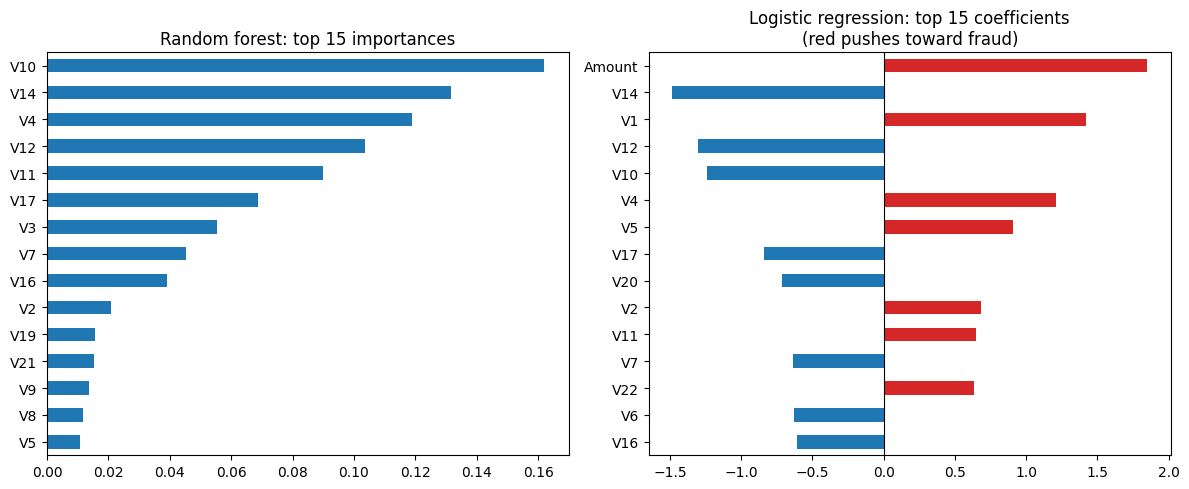

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

imp = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values().tail(15)
imp.plot.barh(ax=axes[0])
axes[0].set_title("Random forest: top 15 importances")

coef = pd.Series(log_model.coef_[0], index=feature_cols)
coef = coef.reindex(coef.abs().sort_values().tail(15).index)
coef.plot.barh(ax=axes[1], color=["tab:red" if v > 0 else "tab:blue" for v in coef])
axes[1].axvline(0, color="k", linewidth=0.8)
axes[1].set_title("Logistic regression: top 15 coefficients\n(red pushes toward fraud)")

plt.tight_layout()
plt.show()

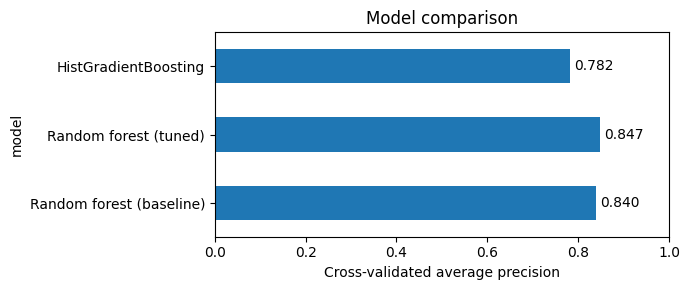

In [24]:
ax = results.set_index("model")["cv_avg_precision"].plot.barh(figsize=(7, 3), xlim=(0, 1))
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.set_xlabel("Cross-validated average precision")
ax.set_title("Model comparison")
plt.tight_layout()
plt.show()

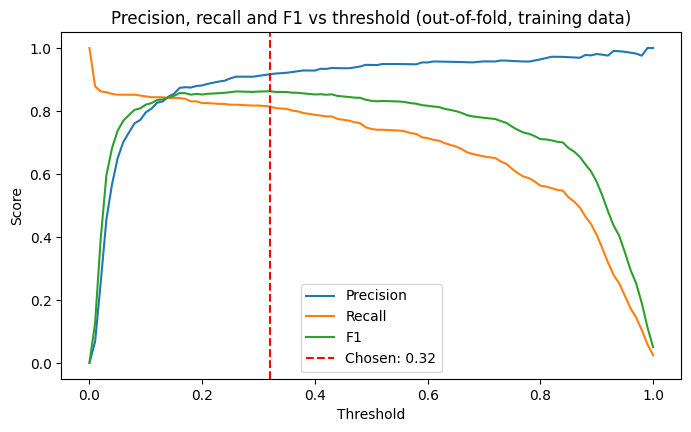

In [25]:
plt.figure(figsize=(8, 4.5))
plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.plot(thr, f1[:-1], label="F1")
plt.axvline(best_t, color="red", linestyle="--", label=f"Chosen: {best_t:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision, recall and F1 vs threshold (out-of-fold, training data)")
plt.legend()
plt.show()

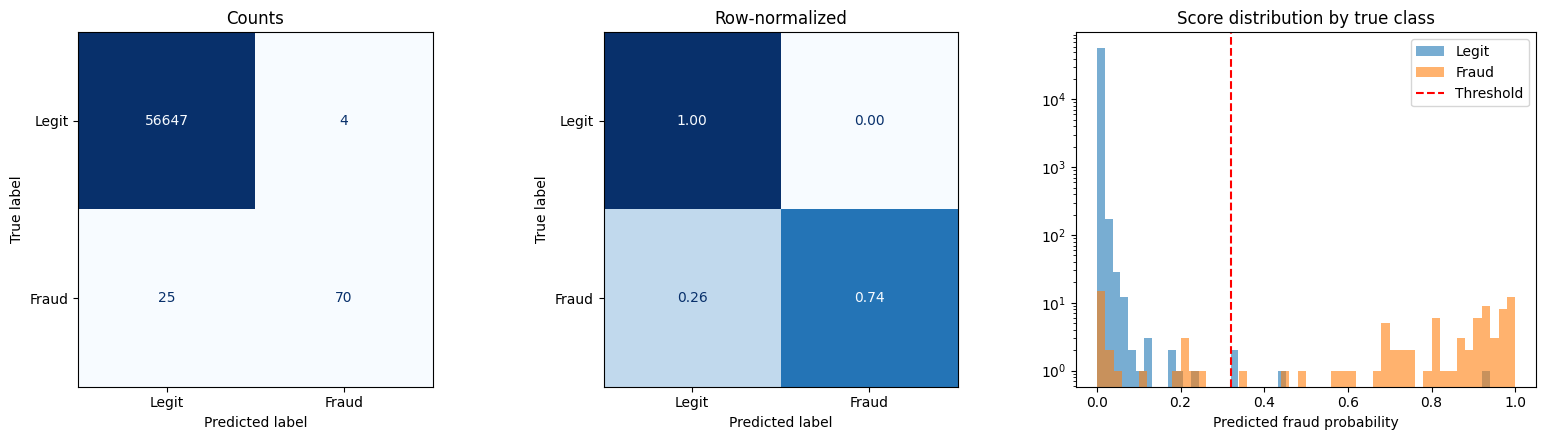

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
labels = ["Legit", "Fraud"]

ConfusionMatrixDisplay.from_predictions(
    y_test, final_pred, ax=axes[0], cmap="Blues",
    colorbar=False, display_labels=labels)
axes[0].set_title("Counts")

ConfusionMatrixDisplay.from_predictions(
    y_test, final_pred, ax=axes[1], normalize="true", values_format=".2f",
    cmap="Blues", colorbar=False, display_labels=labels)
axes[1].set_title("Row-normalized")

axes[2].hist(test_proba[(y_test == 0).values], bins=50, alpha=0.6, label="Legit")
axes[2].hist(test_proba[(y_test == 1).values], bins=50, alpha=0.6, label="Fraud")
axes[2].axvline(best_t, color="red", linestyle="--", label="Threshold")
axes[2].set_yscale("log")
axes[2].set_xlabel("Predicted fraud probability")
axes[2].set_title("Score distribution by true class")
axes[2].legend()

plt.tight_layout()
plt.show()

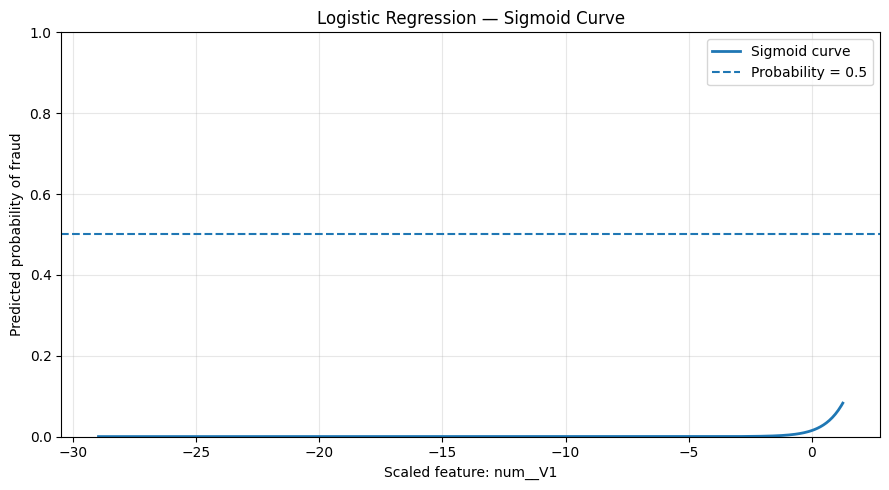

In [27]:

# Select a feature to visualize
feature_names = preprocessor.get_feature_names_out()

# Select the first feature; change this index if needed
feature_idx = 0
feature_name = feature_names[feature_idx]

# Hold all other features at their median values
baseline = np.median(X_train_prepared, axis=0)

# Generate values across the selected feature's range
x_values = np.linspace(
    X_train_prepared[:, feature_idx].min(),
    X_train_prepared[:, feature_idx].max(),
    500
)

# Create inputs for prediction
X_curve = np.tile(baseline, (len(x_values), 1))
X_curve[:, feature_idx] = x_values

# Get fraud probabilities
probabilities = log_model.predict_proba(X_curve)[:, 1]

# Plot
plt.figure(figsize=(9, 5))
plt.plot(x_values, probabilities, linewidth=2, label="Sigmoid curve")
plt.axhline(0.5, linestyle="--", label="Probability = 0.5")

plt.xlabel(f"Scaled feature: {feature_name}")
plt.ylabel("Predicted probability of fraud")
plt.title("Logistic Regression — Sigmoid Curve")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


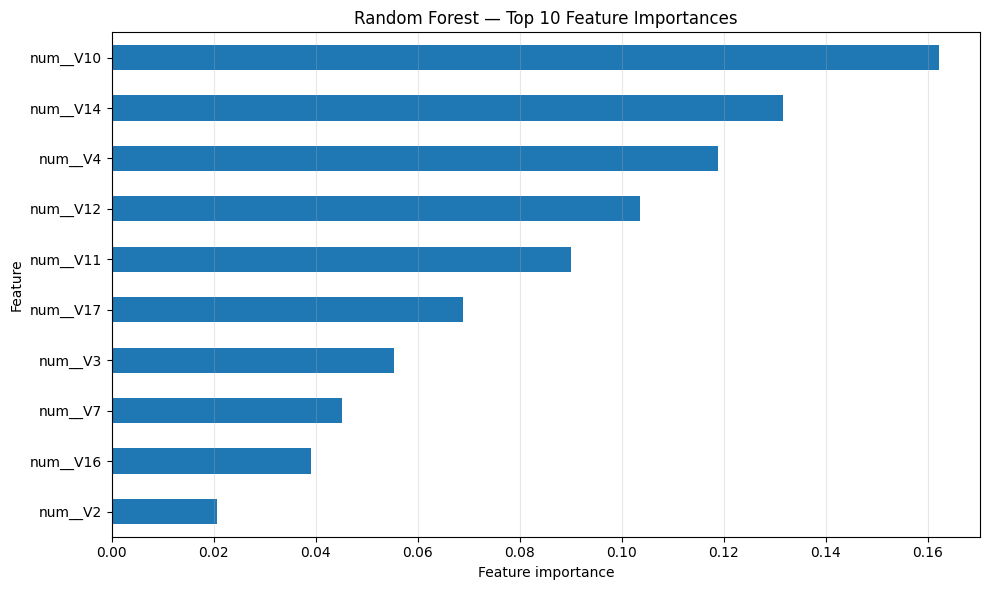

In [28]:

# Get feature names and importance scores
feature_names = preprocessor.get_feature_names_out()

importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(10)

# Plot
plt.figure(figsize=(10, 6))
importance.sort_values().plot(kind="barh")

plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Random Forest — Top 10 Feature Importances")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [29]:

# 1. Create the tuned Random Forest pipeline

tuned_rf_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        max_features=0.3,
        max_depth=None,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# 2. Train using the training dataset
tuned_rf_pipe.fit(X_train, y_train)

print("Tuned Random Forest training completed!")


Tuned Random Forest training completed!


In [30]:

# Predict fraud probabilities on the unseen test data
tuned_proba = tuned_rf_pipe.predict_proba(X_test)[:, 1]

# Use the default threshold of 0.5 for this initial comparison
tuned_pred = (tuned_proba >= 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, tuned_pred))

print("\nClassification Report:")
print(classification_report(y_test, tuned_pred, zero_division=0))

print("ROC-AUC:",
      round(roc_auc_score(y_test, tuned_proba), 4))

print("Average Precision:",
      round(average_precision_score(y_test, tuned_proba), 4))


Confusion Matrix:
[[56650     1]
 [   27    68]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.99      0.72      0.83        95

    accuracy                           1.00     56746
   macro avg       0.99      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC: 0.9337
Average Precision: 0.8091


In [31]:

comparison = pd.DataFrame([
    {
        "Model": "Baseline Random Forest",
        "ROC-AUC": roc_auc_score(
            y_test, rf_pipe.predict_proba(X_test)[:, 1]
        ),
        "Average Precision": average_precision_score(
            y_test, rf_pipe.predict_proba(X_test)[:, 1]
        )
    },
    {
        "Model": "Tuned Random Forest",
        "ROC-AUC": roc_auc_score(y_test, tuned_proba),
        "Average Precision": average_precision_score(
            y_test, tuned_proba
        )
    }
])

print(comparison.round(4))


                    Model  ROC-AUC  Average Precision
0  Baseline Random Forest   0.9299             0.8076
1     Tuned Random Forest   0.9337             0.8091


In [32]:

# Step 1: Select the threshold for the tuned Random Forest

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_recall_curve
import numpy as np

# Re-create the tuned pipeline
tuned_rf_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        max_features=0.3,
        max_depth=None,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Generate out-of-fold probabilities using training data only
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_proba_tuned = cross_val_predict(
    tuned_rf_pipe,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Find the threshold that maximizes F1-score
prec_tuned, rec_tuned, thr_tuned = precision_recall_curve(
    y_train, oof_proba_tuned
)

f1_tuned = (
    2 * prec_tuned * rec_tuned
    / (prec_tuned + rec_tuned + 1e-12)
)

best_idx_tuned = np.argmax(f1_tuned[:-1])
best_t_tuned = thr_tuned[best_idx_tuned]

print("Selected threshold:", round(best_t_tuned, 4))
print("Training OOF precision:", round(prec_tuned[best_idx_tuned], 4))
print("Training OOF recall:", round(rec_tuned[best_idx_tuned], 4))
print("Training OOF F1-score:", round(f1_tuned[best_idx_tuned], 4))


Selected threshold: 0.4048
Training OOF precision: 0.9292
Training OOF recall: 0.7989
Training OOF F1-score: 0.8592


In [33]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Train the tuned model on the complete training split
tuned_rf_pipe.fit(X_train, y_train)

# Predict fraud probabilities on the untouched test split
tuned_test_proba = tuned_rf_pipe.predict_proba(X_test)[:, 1]

# Apply the threshold selected using training OOF predictions
tuned_test_pred = (
    tuned_test_proba >= best_t_tuned
).astype(int)

print("Selected threshold:", round(best_t_tuned, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tuned_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    tuned_test_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("ROC-AUC:",
      round(roc_auc_score(y_test, tuned_test_proba), 4))

print("Average Precision:",
      round(average_precision_score(y_test, tuned_test_proba), 4))

print("Test Precision:",
      round(precision_score(y_test, tuned_test_pred, zero_division=0), 4))

print("Test Recall:",
      round(recall_score(y_test, tuned_test_pred, zero_division=0), 4))

print("Test F1-score:",
      round(f1_score(y_test, tuned_test_pred, zero_division=0), 4))


Selected threshold: 0.4048

Confusion Matrix:
[[56649     2]
 [   25    70]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.97      0.74      0.84        95

    accuracy                           1.00     56746
   macro avg       0.99      0.87      0.92     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC: 0.9337
Average Precision: 0.8091
Test Precision: 0.9722
Test Recall: 0.7368
Test F1-score: 0.8383


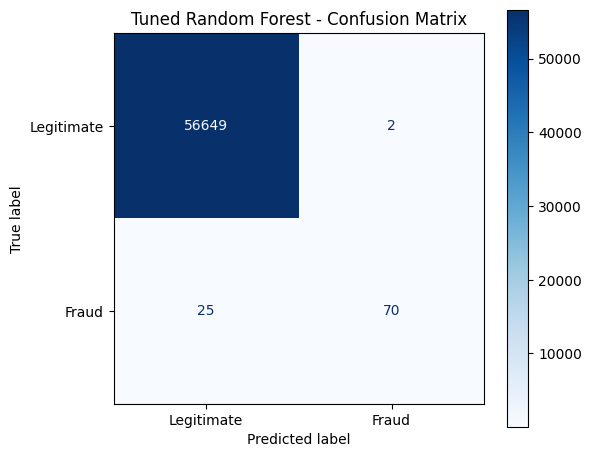

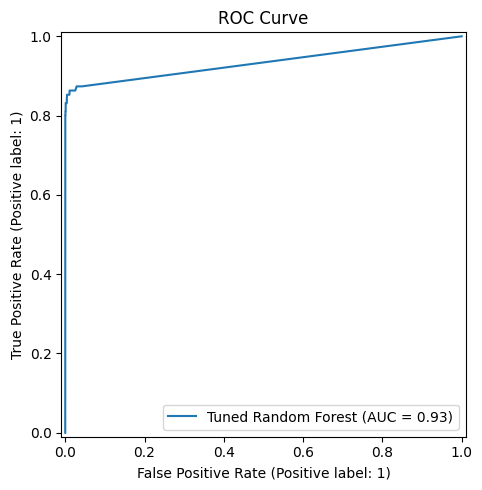

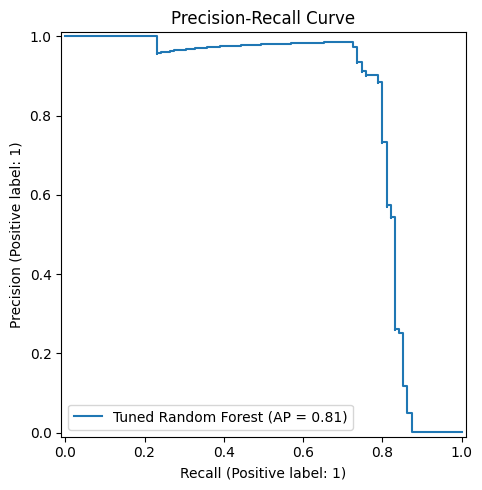

In [34]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# 1. Confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    tuned_test_pred,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    ax=ax
)

ax.set_title("Tuned Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()


# 2. ROC curve
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    tuned_test_proba,
    ax=ax,
    name="Tuned Random Forest"
)

ax.set_title("ROC Curve")
plt.tight_layout()
plt.show()


# 3. Precision-Recall curve
fig, ax = plt.subplots(figsize=(7, 5))

PrecisionRecallDisplay.from_predictions(
    y_test,
    tuned_test_proba,
    ax=ax,
    name="Tuned Random Forest"
)

ax.set_title("Precision-Recall Curve")
plt.tight_layout()
plt.show()


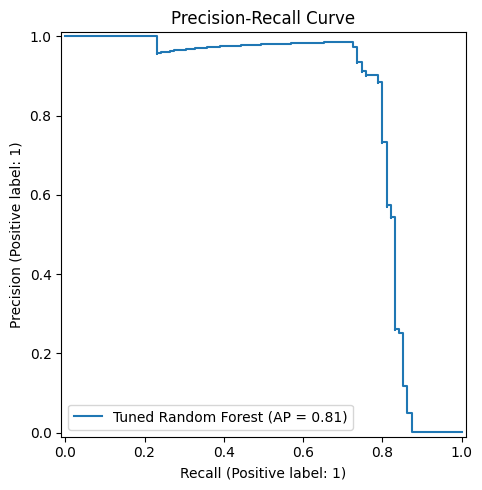

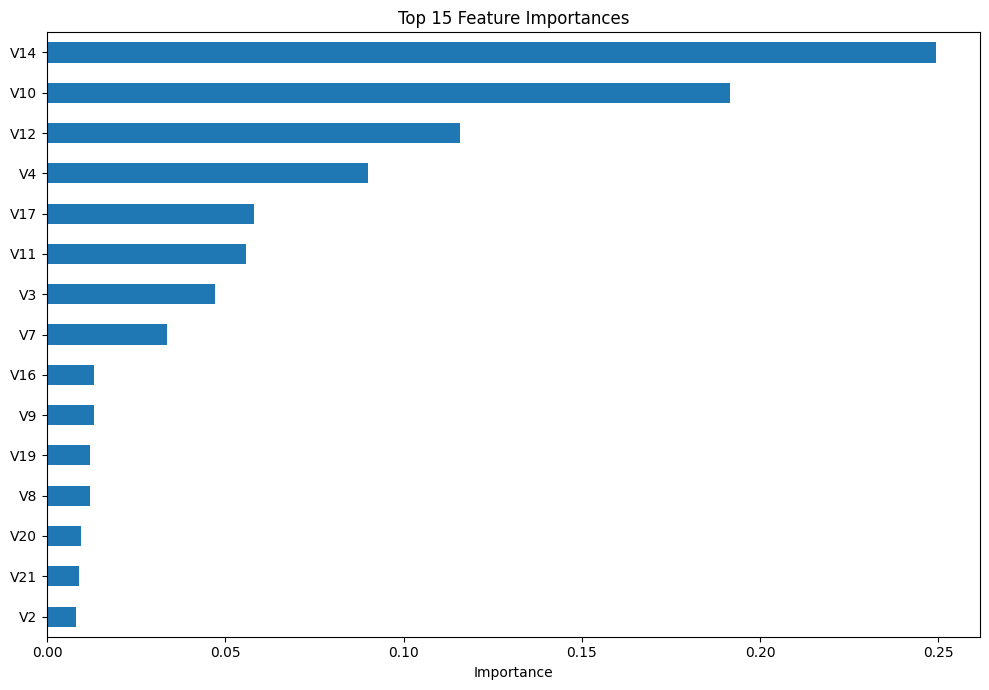

In [35]:

# Precision-Recall curve
fig, ax = plt.subplots(figsize=(7, 5))

PrecisionRecallDisplay.from_predictions(
    y_test,
    tuned_test_proba,
    ax=ax,
    name="Tuned Random Forest"
)

ax.set_title("Precision-Recall Curve")
plt.tight_layout()
plt.show()

# Top 15 feature importances
rf_model = tuned_rf_pipe.named_steps["model"]

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))

feature_importance.head(15).sort_values().plot(
    kind="barh",
    ax=ax
)

ax.set_title("Top 15 Feature Importances")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()


In [36]:

import joblib
import os

# Package the trained pipeline and its decision threshold
final_model_package = {
    "model": tuned_rf_pipe,
    "threshold": float(best_t_tuned),
    "model_name": "Tuned Random Forest",
    "feature_names": list(X_train.columns),
    "metrics": {
        "roc_auc": float(roc_auc_score(y_test, tuned_test_proba)),
        "average_precision": float(
            average_precision_score(y_test, tuned_test_proba)
        ),
        "precision": float(
            precision_score(y_test, tuned_test_pred, zero_division=0)
        ),
        "recall": float(
            recall_score(y_test, tuned_test_pred, zero_division=0)
        ),
        "f1_score": float(
            f1_score(y_test, tuned_test_pred, zero_division=0)
        )
    }
}

# Save the final package
model_path = "fraud_model.joblib"
joblib.dump(final_model_package, model_path)

print("Model saved successfully!")
print("File:", os.path.abspath(model_path))
print("Threshold:", final_model_package["threshold"])
print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")


Model saved successfully!
File: /content/fraud_model.joblib
Threshold: 0.40478010646632273
File size: 4701.41 KB


In [37]:

# Reload the saved package
loaded_package = joblib.load("fraud_model.joblib")

loaded_model = loaded_package["model"]
loaded_threshold = loaded_package["threshold"]

# Verify probabilities and predictions are reproduced
loaded_proba = loaded_model.predict_proba(X_test)[:, 1]
loaded_pred = (loaded_proba >= loaded_threshold).astype(int)

assert np.allclose(loaded_proba, tuned_test_proba)
assert np.array_equal(loaded_pred, tuned_test_pred)

print("Verification passed!")
print("Threshold:", loaded_threshold)
print("Test predictions match:", np.array_equal(
    loaded_pred, tuned_test_pred
))


Verification passed!
Threshold: 0.40478010646632273
Test predictions match: True


In [38]:
from google.colab import files

files.download('/content/fraud_model.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>